import all necessary library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


load all data

In [2]:
orders= pd.read_csv("data/olist_orders_dataset.csv")
order_items= pd.read_csv("data/olist_order_items_dataset.csv")
customers=pd.read_csv("data/olist_customers_dataset.csv")
payments=pd.read_csv("data/olist_order_payments_dataset.csv")

shape shows number of items in the table

In [3]:
print("Orders Shape:", orders.shape)
print("Order Items Shape:", order_items.shape)
print("Customers Shape:", customers.shape)
print("Payments Shape:", payments.shape)

Orders Shape: (99441, 8)
Order Items Shape: (112650, 7)
Customers Shape: (99441, 5)
Payments Shape: (103886, 5)


joining tables on same primary key for more information

In [9]:
order_merged= pd.merge(orders, order_items, on="order_id", how="inner")
full_df = pd.merge(order_merged,customers, on="customer_id", how="inner")

analysis of top 5 revenue by customer state

In [13]:
full_df['total_item_value']= full_df['price']+full_df['freight_value']
#group customer state
state_revenue = full_df.groupby('customer_state')['total_item_value'].sum().reset_index()
state_revenue = state_revenue.sort_values(by='total_item_value', ascending=False)
print("--- Top 5 States by Revenue ---")
print(state_revenue.head(5))

--- Top 5 States by Revenue ---
   customer_state  total_item_value
25             SP        5921678.12
18             RJ        2129681.98
10             MG        1856161.49
22             RS         885826.76
17             PR         800935.44


Analyzing Order Status and Delivery Delays

In [14]:
# 1. Check the distribution of order statuses (delivered, canceled, shipped, etc.)
order_status_counts = orders['order_status'].value_counts(normalize=True) * 100
print("--- Order Status Percentage Breakdown ---")
print(order_status_counts.round(2))

# 2. Convert date columns to actual pandas datetime objects so we can do math with dates
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])
orders['order_delivered_customer_date'] = pd.to_datetime(orders['order_delivered_customer_date'])
orders['order_estimated_delivery_date'] = pd.to_datetime(orders['order_estimated_delivery_date'])

# 3. Calculate total delivery time in days (from purchase to customer delivery)
orders['delivery_time_days'] = (orders['order_delivered_customer_date'] - orders['order_purchase_timestamp']).dt.total_seconds() / (24 * 3600)

# 4. Calculate delivery delay (Actual delivery date minus Estimated delivery date)
# Positive numbers mean late deliveries, negative or zero mean on-time/early.
orders['delivery_delay_days'] = (orders['order_delivered_customer_date'] - orders['order_estimated_delivery_date']).dt.total_seconds() / (24 * 3600)

print("\nAverage Delivery Time (Days):", round(orders['delivery_time_days'].mean(), 2))

# Calculate percentage of orders that arrived after the estimated date
delayed_orders_pct = (orders['delivery_delay_days'] > 0).mean() * 100
print("Percentage of Delayed Orders (%):", round(delayed_orders_pct, 2))

--- Order Status Percentage Breakdown ---
order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64

Average Delivery Time (Days): 12.56
Percentage of Delayed Orders (%): 7.87


Analyzing the Impact of Delivery Delays on Review Scores

In [16]:
# 1. Load the reviews dataset
reviews = pd.read_csv('data/olist_order_reviews_dataset.csv')

# 2. Merge reviews with our existing 'orders' DataFrame using 'order_id'
reviews_df = pd.merge(orders, reviews, on='order_id', how='inner')

# 3. Create a boolean column checking if an order was delayed (delay > 0 days)
reviews_df['is_delayed'] = reviews_df['delivery_delay_days'] > 0

# 4. Group by delay status to see the average review score (1 to 5 scale)
review_summary = reviews_df.groupby('is_delayed')['review_score'].mean().reset_index()

print("--- Average Review Score Impact ---")
# Map True/False to readable labels for display
review_summary['Delivery Status'] = review_summary['is_delayed'].map({False: 'On Time / Early', True: 'Delayed'})
print(review_summary[['Delivery Status', 'review_score']])

--- Average Review Score Impact ---
   Delivery Status  review_score
0  On Time / Early      4.214307
1          Delayed      2.566550


Analyzing Payment Types and Transaction Volumes

In [18]:
# 1. Load the payments dataset
payments = pd.read_csv('data/olist_order_payments_dataset.csv')

# 2. Group by payment type to analyze total revenue, average payment value, and total transactions
payment_summary = payments.groupby('payment_type').agg({
    'payment_value': ['sum', 'mean', 'count']
}).reset_index()

# 3. Flatten and rename multi-level column headers for readability
payment_summary.columns = ['Payment_Type', 'Total_Revenue', 'Avg_Payment_Value', 'Transaction_Count']

# 4. Sort by highest total revenue
payment_summary = payment_summary.sort_values(by='Total_Revenue', ascending=False)

print("--- Payment Methods Breakdown ---")
display(payment_summary.round(2))

--- Payment Methods Breakdown ---


,Payment_Type,Total_Revenue,Avg_Payment_Value,Transaction_Count
1,credit_card,12542084.19,163.32,76795
0,boleto,2869361.27,145.03,19784
4,voucher,379436.87,65.70,5775
2,debit_card,217989.79,142.57,1529
3,not_defined,0.00,0.00,3


Analyzing Top Product Categories by Revenue

In [21]:
# 1. Load products and category name translation datasets
products = pd.read_csv('data/olist_products_dataset.csv')
category_translation = pd.read_csv('data/product_category_name_translation.csv')

# 2. Translate category names from Portuguese to English for readability
products_translated = pd.merge(products, category_translation, on='product_category_name', how='left')

# 3. Merge products into our existing full_df using 'product_id'
full_df_products = pd.merge(full_df, products_translated, on='product_id', how='inner')

# 4. Group by English product category name to find top revenue generators
category_revenue = full_df_products.groupby('product_category_name_english')['total_item_value'].sum().reset_index()
category_revenue = category_revenue.sort_values(by='total_item_value', ascending=False)

print("--- Top 5 Product Categories by Revenue ---")
display(category_revenue.head(5).round(2))

--- Top 5 Product Categories by Revenue ---


,product_category_name_english,total_item_value
43,health_beauty,1441248.07
70,watches_gifts,1305541.61
7,bed_bath_table,1241681.72
65,sports_leisure,1156656.48
15,computers_accessories,1059272.40


Visualizing Top 5 Product Categories

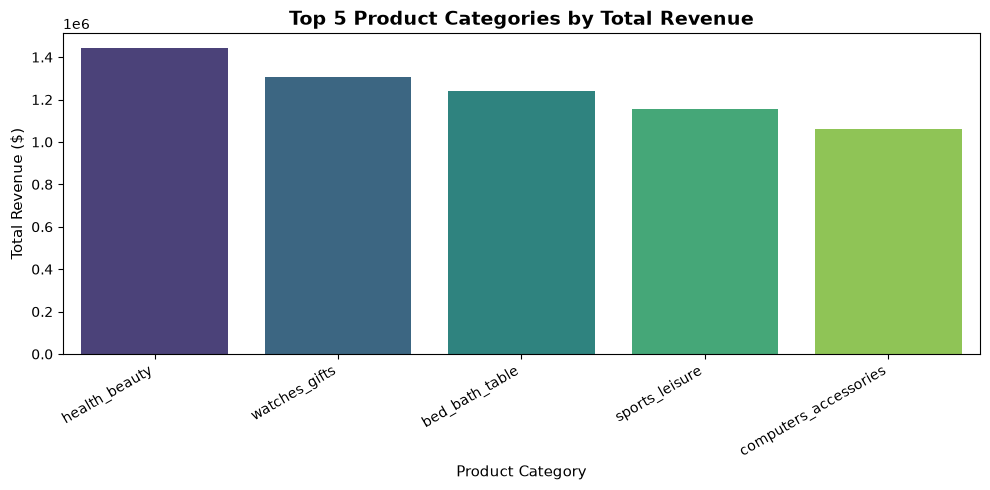

In [22]:
# Set up the visualization figure size
plt.figure(figsize=(10, 5))

# Create a barplot for the top 5 product categories by revenue
sns.barplot(
    data=category_revenue.head(5), 
    x='product_category_name_english', 
    y='total_item_value', 
    hue='product_category_name_english', 
    palette='viridis', 
    legend=False
)

# Add titles and labels
plt.title('Top 5 Product Categories by Total Revenue', fontsize=14, fontweight='bold')
plt.xlabel('Product Category', fontsize=11)
plt.ylabel('Total Revenue ($)', fontsize=11)

# Rotate x-axis labels slightly so category names don't overlap
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()